# DDMPY 0930 与 fibeRIS / MOOSE：方程与用法对比

**围岩中的控制方程相同；当前完整边值问题并非严格相同。**
DDMPY 是无限全空间、零厚度裂缝的解析位移间断解；当前 fibeRIS / MOOSE 是有限域、有限厚度本征应变层的三维有限元近似。
二者都输入开度和滑移、输出三个方向的位移。MOOSE 独立求解弹性平衡，DDMPY 仅用于参考比较。

本文件分别执行两套原生接口，并展示已有 DDMPY 模型的最小迁移方法。表格和图片均来自实际执行。
**打开即可看已保存结果；Run All 会重新运行有限元，预计本机 8 个 MPI 进程约 4–5 分钟。**
完整原例 30 帧的位移、应变、应变率与性能见 [结果 notebook](DDMPY_0930_vs_MOOSE.ipynb)。

## 1. 方程与边界条件

令 $\boldsymbol\varepsilon=\operatorname{sym}\nabla\mathbf u$。均匀各向同性小应变弹性围岩中，两者满足

$$\nabla\cdot\boldsymbol\sigma=0,\qquad
\boldsymbol\sigma=\lambda\operatorname{tr}(\boldsymbol\varepsilon)\mathbf I+2G\boldsymbol\varepsilon,$$
$$G\Delta\mathbf u+(\lambda+G)\nabla(\nabla\cdot\mathbf u)=0,\qquad
G=\frac{E}{2(1+\nu)},\quad\lambda=\frac{E\nu}{(1+\nu)(1-2\nu)}.$$

| 条件 | 原版 DDMPY 0930 | 当前 fibeRIS → MOOSE |
|---|---|---|
| 裂缝 | 有限矩形、零厚度位移间断面 $S$ | 有限矩形、厚度为 $t$ 的本征应变层 |
| 给定输入 | $[\mathbf u]=\mathbf u^+-\mathbf u^-=\mathbf b=(S1,S2,width)$ | $\boldsymbol\varepsilon_t^*=\operatorname{sym}(\mathbf b\otimes\mathbf n)\chi_{band}/t$ |
| 面力/本构 | 同一法向下 $\boldsymbol\sigma^+\mathbf n=\boldsymbol\sigma^-\mathbf n$ | $\boldsymbol\sigma=\mathsf C:(\boldsymbol\varepsilon-\boldsymbol\varepsilon_t^*)$，弱形式平衡 |
| 外边界 | 无限远 $\mathbf u\to0$ | 立方体六个远端表面 $\mathbf u=0$ |
| 时间 | 一系列准静态构型 | 一系列静态平衡，无惯性或波动项 |

MOOSE 在薄层外满足同一 Navier 方程；实际整体弱形式是

$$\int_{\Omega_L}\varepsilon(\mathbf v):\mathsf C:\varepsilon(\mathbf u)\,dV
=\int_{\Omega_L}\varepsilon(\mathbf v):\mathsf C:\varepsilon_t^*\,dV.$$

局部法向为 $\mathbf e_3$ 时，$\varepsilon^*_{33}=width/t$，
$\varepsilon^*_{13}=\varepsilon^*_{31}=S1/(2t)$，
$\varepsilon^*_{23}=\varepsilon^*_{32}=S2/(2t)$。
薄层使用相同弹性模量，有限厚度下位移连续，**没有严格的零厚度位移跳跃约束**；逐点面力跳跃误差尚未单独验证。
理想间断的源项可写为 $\operatorname{sym}(\mathbf b\otimes\mathbf n)\delta_S$，薄层对它作正则化。
离开奇异处，需结合薄层厚度、网格分辨率与计算域收敛验证，才能量化对 DDMPY 的逼近。

两者均以开度/滑移为输入，不是给定压力后反求开度，也一般不是无面力自由裂缝。
对当前均匀介质、给定跳跃，固定泊松比后整体缩放 E 不改变位移解，但改变应力尺度。
DDMPY 的 `Element.mu` 表示泊松比，不是剪切模量 G。
约定来源：原始 `DDMpy_0930/Element.py` 的跳跃注释与位移公式，以及 `fiberis/moose/numerical_ddm.py` 的实际输入生成。

In [1]:
from pathlib import Path
import sys, json, hashlib, time
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'fibeRIS').is_dir() and (p/'scripts/numerical_ddm').is_dir()),
            Path('/rcp/rcp42/home/shenyaojin/Documents/bakken_mariner'))
sys.path[:0] = [str(ROOT), str(ROOT/'fibeRIS/src')]
from scripts.tensile_fault.data_transfer.from_pc import DDMpy_0930 as ddmpy
from fiberis.moose import numerical_ddm as fem
OUT = ROOT/'output/numerical_ddm/usage_comparison'
OUT.mkdir(parents=True, exist_ok=True)
manifest = json.loads((ROOT/'output/numerical_ddm/notebook_existing_tensile_shear/reference_sha256.json').read_text())
for name, digest in manifest.items():
    assert hashlib.sha256((ROOT/name).read_bytes()).hexdigest() == digest, name
print('Python:', sys.executable)
print('原版 0930 源文件 SHA256 核对通过；源码未修改。')

Python: /rcp/rcp42/home/shenyaojin/miniforge/bin/python
原版 0930 源文件 SHA256 核对通过；源码未修改。


## 2. 相同物理输入，两套建模接口

SI 单位 m、Pa、s。中心原点，裂缝面 x3=0；局部与全局坐标一致。
`length` 是 x1 向长度，`height` 是 x2 向面内高度，`width` 是给定物理张开量。
**数值层厚度另行配置，不等于 height 或 width。**
101 个预定井点全部参与比较；无标距平滑，避开裂缝面及边缘。

In [2]:
length, height, width = 100., 60., 0.001
S1, S2, nu = 0., 0., 0.3
center = (0., 0., 0.)
x = np.linspace(-100., 100., 101)
y, z = np.full_like(x,17.), np.full_like(x,40.)
points = np.column_stack([x,y,z])
print('矩形长度、高度 / m:', length, height)
print('给定跳跃 (S1,S2,width) / m:', (S1,S2,width))
print('井点数:', len(points))

矩形长度、高度 / m: 100.0 60.0
给定跳跃 (S1,S2,width) / m: (0.0, 0.0, 0.001)
井点数: 101


### A. 原版 DDMPY 0930

保留模块嵌套 `Element.Element`、`Well.Well`、`Fracture.FractureZ`。
这里只建模，尚未调用解析计算。构造器自动处理内部负号储存约定，用户输入正张开无需自行取反。

In [3]:
ddm_element = ddmpy.Element.Element(length,height,width,S1=S1,S2=S2)
ddm_element.mu = nu
ddm_element.set_global_coors(*center)
ddm_well = ddmpy.Well.Well().set_well_path(x,y,z)
analytic = ddmpy.Fracture.FractureZ()
analytic.set_fracture_elements(ddm_element)
analytic.set_monitor_wells(ddm_well)
print('DDMPY 模型已创建。')

DDMPY 模型已创建。


### B. fibeRIS 的 MOOSE 后端

新类直接导出为 `Element`、`Well`、`FractureZ`，建模方法相近。
`.configure(config)` 单独配置 E、泊松比、网格、域大小与层厚。
使用二次 HEX27、5 阶积分和 8 个 MPI 进程。可执行程序已在原有 **moose conda 环境**编译；
这里的 Python 使用能导入原版 DDMPY/JIN_pylib 的 base 环境，MPI 显式指向 moose 环境。

In [4]:
config = fem.NumericalConfig(
    executable=str(ROOT/'moose_env/moose/modules/combined/combined-opt'),
    output_directory=str(OUT/'opening_native_h7p5'),
    youngs_modulus=30e9, poissons_ratio=nu,
    half_extent=800., core_extent=120., mesh_size=7.5,
    band_thickness=2., band_cells=2, processors=8,
    mpiexec=str(Path.home()/'miniforge/envs/moose/bin/mpiexec'))

fem_element = fem.Element(length,height,width,S1=S1,S2=S2)
fem_element.mu = nu
fem_element.set_global_coors(*center)
fem_well = fem.Well().set_well_path(x,y,z)
numerical = fem.FractureZ()
numerical.set_fracture_elements(fem_element)
numerical.set_monitor_wells(fem_well)
numerical.configure(config)
assert Path(config.executable).is_file()
print('MOOSE 模型已创建；E=30 GPa，nu=0.3，层厚=2 m，核心网格最大尺寸=7.5 m。')

MOOSE 模型已创建；E=30 GPa，nu=0.3，层厚=2 m，核心网格最大尺寸=7.5 m。


### C. 已有 DDMPY 脚本的最小修改

若已有 `analytic`，可直接导入物理模型：

```python
numerical = fem.from_ddmpy(analytic, config)
numerical.calculate()
result_well = numerical.monitor_wells[0]
```

下面实际执行转换、核对几何。此时 DDMPY 尚未求解，适配器不需要任何参考位移。
后面只求解 B 的等价模型一次。原单位若为英尺，用 `length_scale=0.3048` 一并转换几何、跳跃、井长与标距；时间另行转为秒。

In [5]:
imported = fem.from_ddmpy(analytic,config)
assert not hasattr(analytic.monitor_wells[0],'u1')
np.testing.assert_allclose(imported.elements[0].jump,numerical.elements[0].jump)
np.testing.assert_allclose(imported.elements[0].center,numerical.elements[0].center)
np.testing.assert_allclose(imported.monitor_wells[0].points,numerical.monitor_wells[0].points)
assert (imported.elements[0].length,imported.elements[0].height)==(length,height)
print('转换与原生模型一致，未调用解析求解或导入参考位移。')

转换与原生模型一致，未调用解析求解或导入参考位移。


## 3. 求解与读取

两者都调用 `.calculate()`，然后从 `fracture.monitor_wells[0]` 读取 `u1,u2,u3,strain,mds`。
`set_monitor_wells()` 会复制井，应读取裂缝对象内部的井，而非原先外部井变量。

In [6]:
started = time.perf_counter()
analytic.calculate()
ddmpy_seconds = time.perf_counter()-started
reference_well = analytic.monitor_wells[0]
reference_u = np.column_stack([reference_well.u1,reference_well.u2,reference_well.u3])
reference_strain = reference_well.strain.copy()
np.savez(OUT/'original_0930.npz',points=points,displacement=reference_u,
         strain=reference_strain,md=reference_well.mds)
print(f'原版 DDMPY calculate() 实际耗时：{ddmpy_seconds:.6f} s')

原版 DDMPY calculate() 实际耗时：0.001763 s


In [7]:
# 本格实际生成输入并运行 MOOSE；不是加载 DDMPY 位移或复制旧结果。
numerical.calculate()
result_well = numerical.monitor_wells[0]
numerical_u = np.column_stack([result_well.u1,result_well.u2,result_well.u3])
numerical_strain = result_well.strain.copy()
np.testing.assert_allclose(result_well.mds,reference_well.mds)

case = Path(config.output_directory)
run = json.loads((case/'run.json').read_text())
assert run['success'] and run['returncode']==0
assert run['input_sha256']==hashlib.sha256((case/'model.i').read_bytes()).hexdigest()
raw = np.atleast_1d(np.genfromtxt(case/'solution_receivers_0001.csv',delimiter=',',names=True))
raw = np.sort(raw,order='id')
np.testing.assert_allclose(np.column_stack([raw[k] for k in 'xyz']),points,rtol=0,atol=1e-10)
np.testing.assert_allclose(np.column_stack([raw[k] for k in ['ux','uy','uz']]),numerical_u,rtol=0,atol=0)
print('MOOSE 成功退出；Python 位移与原始 CSV 完全一致。')
print('实际命令：',(case/'command.txt').read_text().strip())
print(f"MOOSE 实际耗时：{run['elapsed_seconds']:.3f} s")

MOOSE 成功退出；Python 位移与原始 CSV 完全一致。
实际命令： /rcp/rcp42/home/shenyaojin/miniforge/envs/moose/bin/mpiexec -n 8 /rcp/rcp42/home/shenyaojin/Documents/bakken_mariner/moose_env/moose/modules/combined/combined-opt -i model.i --n-threads=1
MOOSE 实际耗时：295.122 s


## 4. 实测表现

相对 L2：$\|q_{FE}-q_{DDM}\|_2/\|q_{DDM}\|_2$；
峰值归一化最大误差：$\max|q_{FE}-q_{DDM}|/\max|q_{DDM}|$。
使用全部预定点、全部三个位移分量，不采用接近零处的逐点相对误差。

应变由井上位移差投影到切向得到；两者使用相同差分和端点处理。
下面另将 DDMPY 位移送入共同后处理并核对原版结果。
应变指标是**相同离散观测算子下的两种位移场差异**，不包含共同空间差分本身相对连续导数的误差。
此前独立细采样解析导数检查中，此网格含端点处理的总应变误差为 0.7984%，见结果 notebook。

In [8]:
_,_,common_reference_strain = fem.axial_response(points,reference_u)
np.testing.assert_allclose(common_reference_strain,reference_strain,rtol=1e-12,atol=1e-18)
def error_metrics(value,reference):
    error = np.asarray(value)-reference
    return {'相对 L2 (%)':100*np.linalg.norm(error)/np.linalg.norm(reference),
            '峰值归一化最大误差 (%)':100*np.max(abs(error))/np.max(abs(reference)),
            '最大绝对误差':float(np.max(abs(error)))}
metrics = {'三分量位移 / m':error_metrics(numerical_u,reference_u),
           '井轴向应变 / 1':error_metrics(numerical_strain,reference_strain)}
display(pd.DataFrame(metrics).T)
display(pd.DataFrame([
    {'方法':'原版 DDMPY 0930','耗时 / s':ddmpy_seconds,'进程数':1},
    {'方法':'MOOSE 三维有限元','耗时 / s':run['elapsed_seconds'],'进程数':run['processors']}]).set_index('方法'))
print('时间口径：DDMPY calculate()；MOOSE 启动、网格、组装、求解与输出。不含编译和绘图。')
print('MOOSE 子进程 CPU 时间 / s:',run['cpu_seconds'])
print('子进程最大 RSS / GiB:',run['child_maxrss_kib']/1024**2,
      '（getrusage 指标，不是所有 MPI 进程的聚合峰值）')
(OUT/'usage_metrics.json').write_text(json.dumps(dict(metrics=metrics,
    ddmpy_calculate_seconds=ddmpy_seconds,moose_run=run),indent=2,ensure_ascii=False))
np.savez(OUT/'comparison.npz',points=points,md=result_well.mds,
    numerical_u=numerical_u,reference_u=reference_u,
    numerical_strain=numerical_strain,reference_strain=reference_strain)

时间口径：DDMPY calculate()；MOOSE 启动、网格、组装、求解与输出。不含编译和绘图。
MOOSE 子进程 CPU 时间 / s: 2346.017383
子进程最大 RSS / GiB: 7.258235931396484 （getrusage 指标，不是所有 MPI 进程的聚合峰值）


,相对 L2 (%),峰值归一化最大误差 (%),最大绝对误差
三分量位移 / m,0.054021,0.049726,1.217753e-07
井轴向应变 / 1,0.361365,0.662734,6.744645e-09


,耗时 / s,进程数
方法,,
原版 DDMPY 0930,0.001763,1
MOOSE 三维有限元,295.122022,8


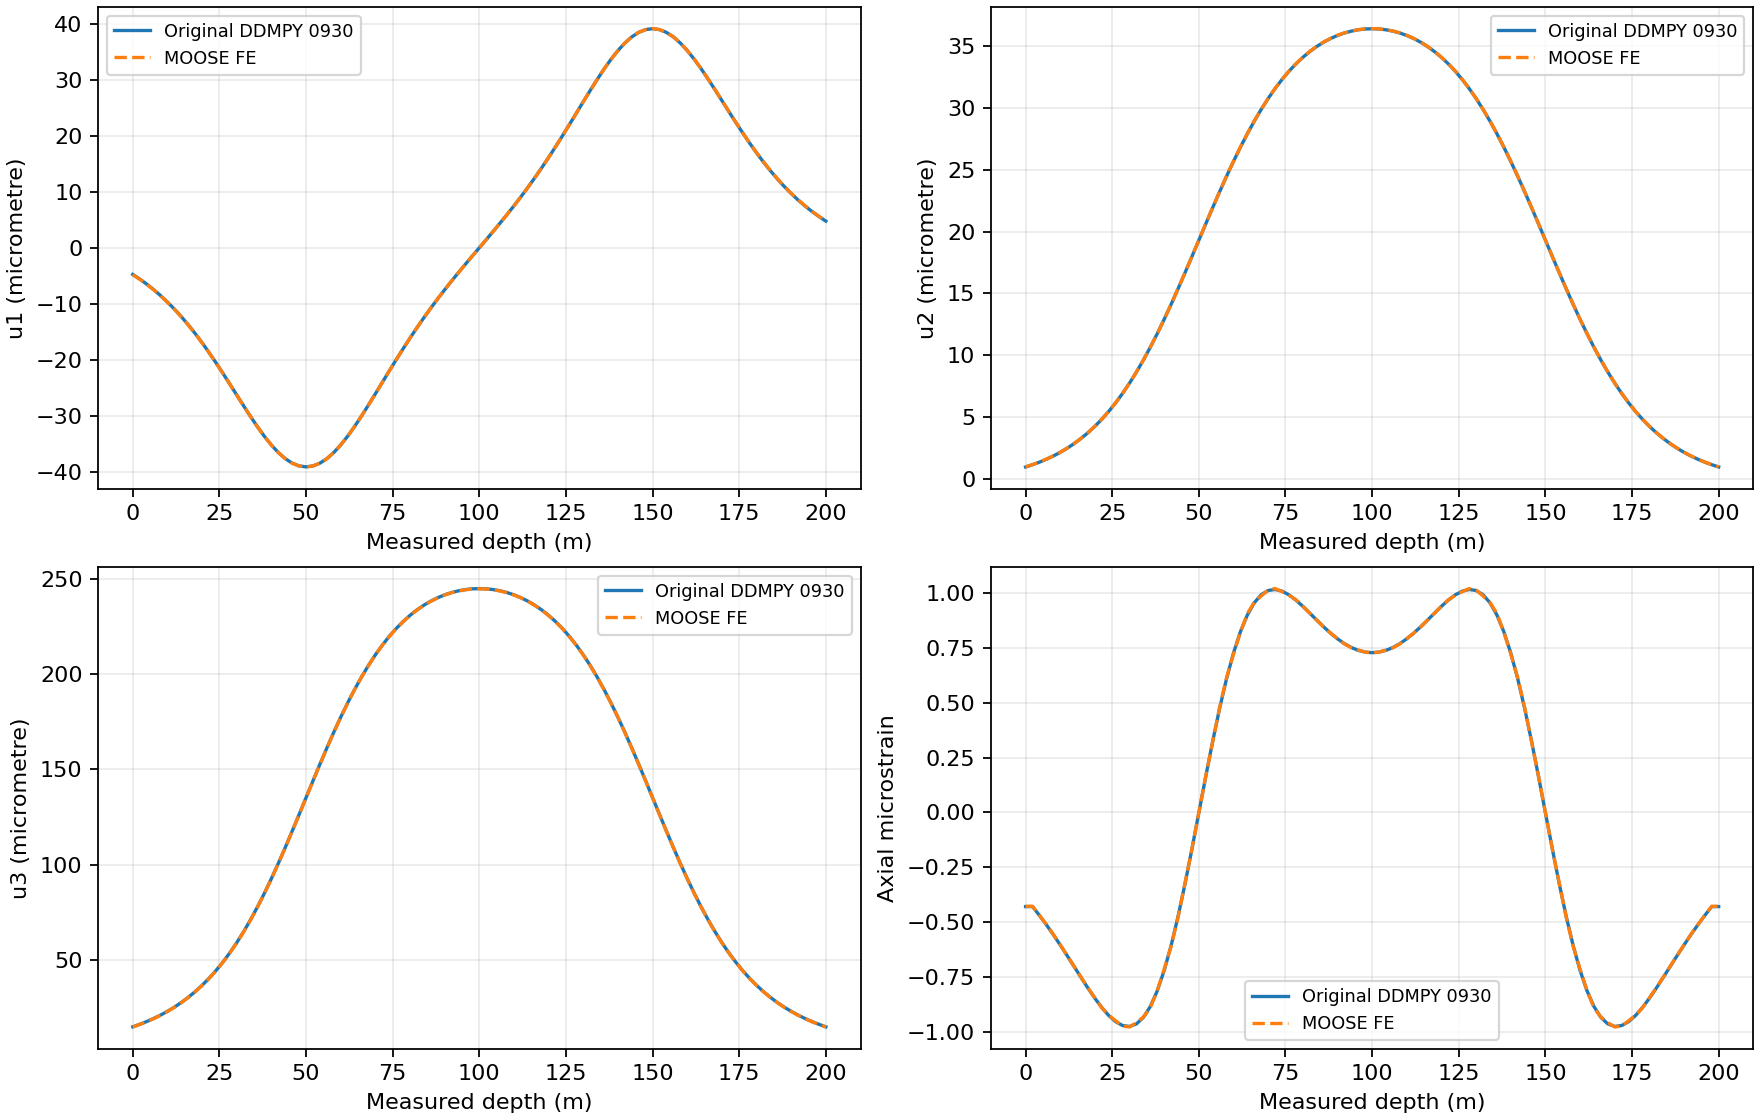

In [9]:
fig,axes = plt.subplots(2,2,figsize=(11,7),constrained_layout=True)
for k,ax in enumerate(list(axes.flat)[:3]):
    ax.plot(result_well.mds,reference_u[:,k]*1e6,label='Original DDMPY 0930')
    ax.plot(result_well.mds,numerical_u[:,k]*1e6,'--',label='MOOSE FE')
    ax.set(xlabel='Measured depth (m)',ylabel=f'u{k+1} (micrometre)')
ax = axes.flat[3]
ax.plot(result_well.mds,reference_strain*1e6,label='Original DDMPY 0930')
ax.plot(result_well.mds,numerical_strain*1e6,'--',label='MOOSE FE')
ax.set(xlabel='Measured depth (m)',ylabel='Axial microstrain')
for ax in axes.flat:
    ax.grid(alpha=.25)
    ax.legend(fontsize=8)
fig.savefig(OUT/'usage_comparison.png',dpi=160)
fig.savefig(OUT/'usage_comparison.pdf')
plt.close(fig)
display(Image(filename=str(OUT/'usage_comparison.png')))

## 5. 用法速查与范围

| 操作 | 原版 DDMPY | fibeRIS / MOOSE |
|---|---|---|
| 单矩形 | `ddmpy.Element.Element(L,H,w,S1=...,S2=...)` | `fem.Element(L,H,w,S1=...,S2=...)` |
| 井 | `ddmpy.Well.Well().set_well_path(x,y,z)` | `fem.Well().set_well_path(x,y,z)` |
| 多矩形、多井 | 向两个 setter 传入 list | 同样传入 list |
| 求解 | `.calculate()` | 先 `.configure(config)`，再 `.calculate()` |
| 输出 | 内部井的 `u1,u2,u3,strain,mds` | 同名字段，全局对象的坐标区别见下文 |
| 导入旧模型 | — | `fem.from_ddmpy(fracture,config)` |
| 旋转平移 | `ddmpy.Fracture.FractureGlobal().set_global_coors(...)` | `fem.FractureGlobal().set_global_coors(...)` |
| 矩形准静态历史 | `ddmpy.DynamicFracture.RectangularFracture()` | `fem.RectangularFracture()`，逐帧真实求解 |
| 历史定义 | `.define_LHW(taxis,length,heigth,width,S1,S2)` | 相同含义，保留原版 `heigth` 拼写 |
| 收集应变 | `.gather_strain_data()` 返回 JIN 容器 | 同名方法返回 fibeRIS Data2D：`.data,.taxis,.daxis` |
| 应变率 | 原例 `take_time_diff()`：后向区间斜率 | `.gather_strain_rate_data()`：非均匀时间轴点导数 |

- 原版 `FractureGlobal.monitor_wells` 的位移是局部分量，新接口返回用户全局分量。
  `R,origin = numerical.frame()` 后，`U_local = U_global @ R.T`；本例两套坐标相同。
- 原版将恰好 90° 微调 0.001 rad；`from_ddmpy` 保留它，新建数值对象默认精确给定角度。
- 有限标距时，新井默认按弧长加权，适配器保留原版按采样点平均。
  需要原始兼容时可在建模时指定 `well.gauge_method='sample_mean'` 和 `well.gauge_length`。
- 时间区间斜率与节点导数不能混用；分钟应换为秒，并明确是否扣除首帧。
- `DynamicFracture` 是准静态，不是动力学。固定几何且所有跳跃共用幅度历史时可用
  `sample_history(points,times_seconds,factors)`，初始幅度须为零。真实 30 帧对比见 [结果 notebook](DDMPY_0930_vs_MOOSE.ipynb)。

对于当前均匀全空间理想问题，DDMPY 解析计算成本显著更低。这里的 MOOSE 实现用于独立数值复现和建立后续有限元基础；
异质介质、接触、流动和惯性等扩展尚未在本接口实现验证。
本例误差不能推广到任意位置/网格/时间历史；已有变化几何算例的应变率误差约 3.18%，尚未达到 1%。
更多已支持及未验证功能见 [兼容范围](COMPATIBILITY.md) 和 [实测汇总](../../output/numerical_ddm/RESULTS.md)。

## 6. 一条命令重新运行本 notebook

在工作区根目录：

```bash
~/miniforge/bin/python scripts/numerical_ddm/build_usage_notebook.py
```

此命令真实执行各代码单元，重新运行两套模型并保存输出，不需要 Jupyter 服务器。
MOOSE 重新编译用 `bash scripts/numerical_ddm/build.sh`，脚本激活原有 moose conda 环境。
本例全部输入和日志位于 `output/numerical_ddm/usage_comparison/opening_native_h7p5/`。
在该目录执行 `command.txt` 中的命令，可用独立 `model.i` 脱离 Python/DDMPY 运行 MOOSE。